# Cải tiến Extra Trees

Chạy sau `final_evaluation.ipynb`. Dự đoán ngoài fold trên train nhận đúng **343/807 mẫu Cao** (recall tính gộp **0,4250**, trung bình qua năm fold **0,4251**). Chênh lệch F1 macro giữa phần huấn luyện và kiểm định của A0 là **0,3860**.

| Mã | Thay đổi |
|---|---|
| A0 | Extra Trees ban đầu đã chốt |
| A1 | Thêm tỷ lệ SO₂ và chọn đặc trưng trong Pipeline |
| A2 | Cân bằng trọng số lớp và đặt kích thước lá tối thiểu bằng 3 |
| A3 | Điều chỉnh điểm lớp Cao, chọn hệ số bằng CV lồng 3 fold |
| A4 | Kết hợp A2 và A3 |

`RUN = False` đọc kết quả có sẵn. Đổi thành `True` để tính lại ablation và đường cong kiểm định trên train. Kết quả test hiển thị ở cuối được đọc từ lần đánh giá riêng, theo hướng dẫn trong README.


In [ ]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.improvement import choose_improved, run_improvement

OUT = ROOT / 'output'
NAME0 = 'Extra Trees ban đầu'
RUN = False


## 1. Đối chiếu mốc và kết quả trên 5 fold

Ứng viên cần tăng F1 macro trung bình và tốt hơn A0 ở ít nhất 4/5 fold. Nếu có nhiều ứng viên đạt ngưỡng, chọn cấu hình có F1 macro CV cao nhất.


In [4]:
if RUN:
    run_improvement(ROOT, n_jobs=2)

candidate = choose_improved(OUT)
abl = pd.read_csv(OUT / 'ablation_results.csv')
baseline = abl.loc[abl.code == 'A0', 'f1_macro_mean'].item()
print(f'{NAME0} khớp mốc CV đã chốt: {baseline:.6f}')

columns = ['code', 'f1_macro_mean', 'f1_macro_std', 'delta_f1_macro',
           'recall_high_mean', 'precision_high_mean', 'folds_better', 'gap_f1_macro']
abl[columns].replace({'code': {'A0': NAME0}}).round(4)


Extra Trees ban đầu khớp mốc CV đã chốt: 0.613950


,code,f1_macro_mean,f1_macro_std,delta_f1_macro,recall_high_mean,precision_high_mean,folds_better,gap_f1_macro
0,Extra Trees ban đầu,0.6140,0.0174,0.0000,0.4251,0.6332,0,0.3860
1,A1,0.5902,0.0104,-0.0238,0.4164,0.5972,0,0.4098
2,A2,0.5988,0.0147,-0.0152,0.6741,0.4928,1,0.2931
3,A3,0.6229,0.0142,0.0089,0.5638,0.5584,4,0.3771
4,A4,0.5988,0.0147,-0.0152,0.6741,0.4928,1,0.2931


## 2. Hệ số lớp Cao và độ phức tạp của cây

Bảng ghi hệ số được chọn trong từng fold ngoài. Đồ thị giúp đối chiếu F1 macro huấn luyện và kiểm định khi thay đổi độ sâu hoặc kích thước lá.


fold,1,2,3,4,5
code,,,,,
A3,1.25,1.5,1.25,1.25,1.5
A4,1.00,1.0,1.00,1.00,1.0


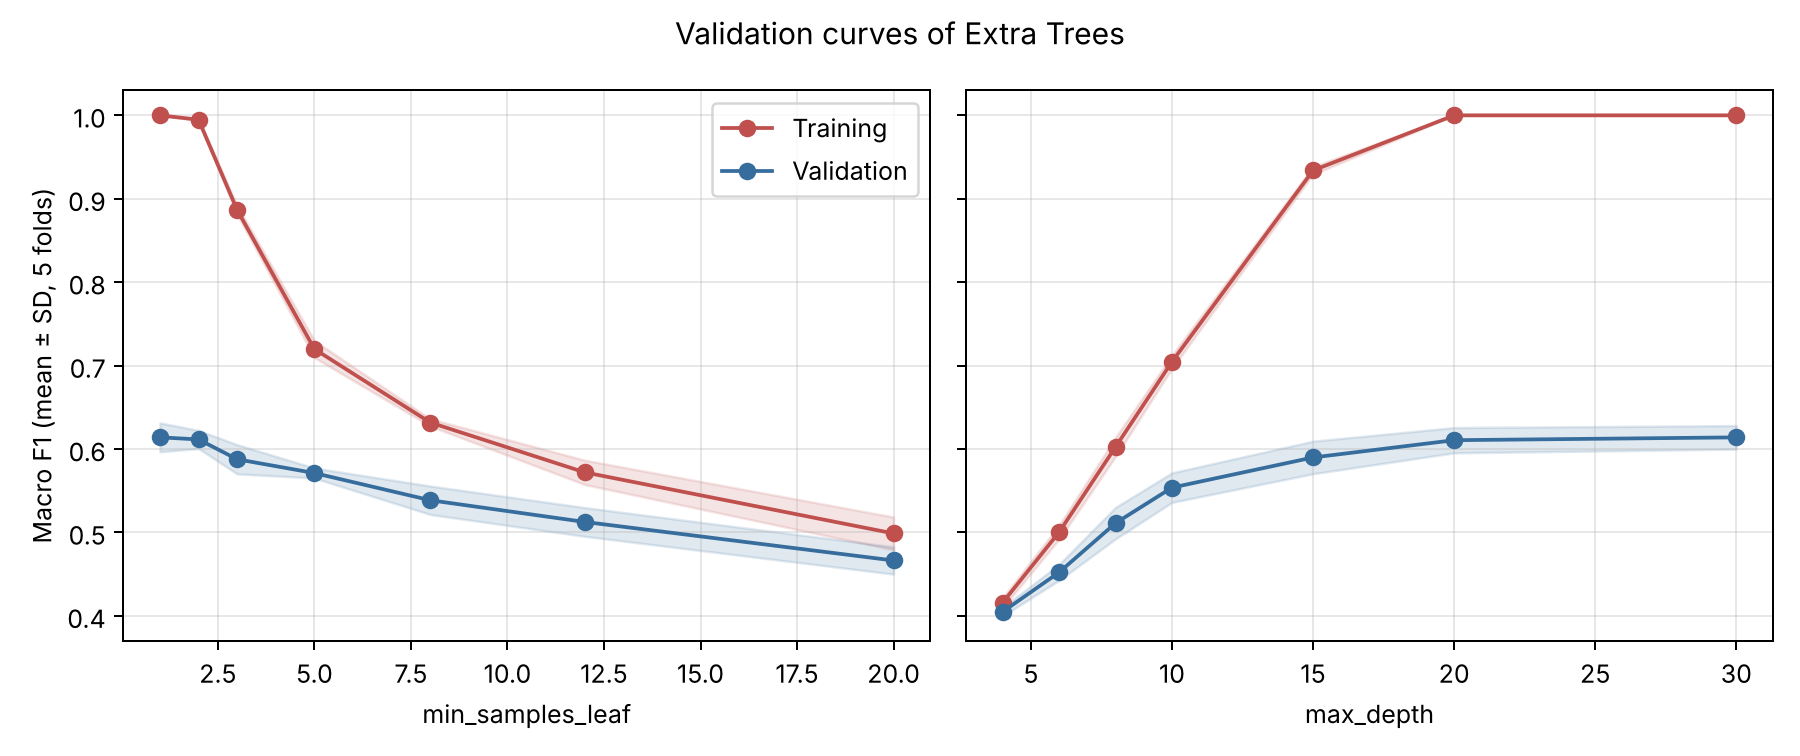

In [9]:
weights = pd.read_csv(OUT / 'ablation_decision_weights.csv')
display(weights.pivot(index='code', columns='fold', values='high_weight'))
display(Image(filename=str(OUT / 'figures' / 'validation_curve_extra_trees.png')))


## 3. Ứng viên cải tiến được chọn theo CV

Bước này đọc kết quả CV trên train. Extra Trees ban đầu là mô hình chính được chốt ở vòng so sánh ban đầu.


In [12]:
if candidate is None:
    print('Chưa có cấu hình đạt tiêu chí cải tiến.')
else:
    columns = ['code', 'change', 'f1_macro_mean', 'f1_macro_std', 'delta_f1_macro', 'folds_better']
    print(candidate[columns].to_string())


code                                                             A3
change            + hệ số quyết định cho lớp Cao (chọn bằng CV l...
f1_macro_mean                                              0.622854
f1_macro_std                                               0.014224
delta_f1_macro                                             0.008904
folds_better                                                      4


## 4. Đối chiếu kết quả đã lưu trên test

Hai cấu hình dùng cùng tập kiểm tra. Các bảng mô tả thay đổi giữa các lớp sau khi ứng viên đã được chốt.


In [13]:
decision_path = OUT / 'improved_decision.json'
result_files = [
    'test_metrics.json', 'improved_test_metrics.json',
    'test_classification_report.csv', 'improved_test_classification_report.csv',
    'improved_test_confusion_matrix.csv',
]

if not decision_path.is_file():
    print('Chưa có quyết định và kết quả test cho ứng viên cải tiến. Xem README để tạo kết quả lần đầu.')
else:
    decision = json.loads(decision_path.read_text(encoding='utf-8'))
    missing_files = [name for name in result_files if not (OUT / name).is_file()]
    if missing_files:
        print('Kết quả test chưa đủ tệp:', ', '.join(missing_files))
    elif (candidate is None or decision['code'] != candidate.code
          or abs(decision['selection_cv_mean'] - candidate.f1_macro_mean) > 1e-6):
        print('Kết quả test đã lưu thuộc một quyết định CV khác. Đối chiếu lại các tệp của cùng lần chạy.')
    else:
        improved_name = f"Extra Trees cải tiến ({decision['code']})"
        base = json.loads((OUT / 'test_metrics.json').read_text(encoding='utf-8'))
        improved = json.loads((OUT / 'improved_test_metrics.json').read_text(encoding='utf-8'))
        comparison = pd.DataFrame({NAME0: base, improved_name: improved})
        comparison['Chênh lệch'] = comparison[improved_name] - comparison[NAME0]
        display(comparison.round(4))

        labels = ['Thấp', 'Trung bình', 'Cao']
        metrics = ['precision', 'recall', 'f1-score']
        base_report = pd.read_csv(OUT / 'test_classification_report.csv', index_col=0)
        improved_report = pd.read_csv(OUT / 'improved_test_classification_report.csv', index_col=0)
        display(pd.concat({
            NAME0: base_report.loc[labels, metrics],
            improved_name: improved_report.loc[labels, metrics],
        }, axis=1).round(4))
        display(pd.read_csv(OUT / 'improved_test_confusion_matrix.csv', index_col=0))


,Extra Trees ban đầu,Extra Trees cải tiến (A3),Chênh lệch
accuracy,0.6024,0.5921,-0.0103
balanced_accuracy,0.5752,0.5867,0.0116
f1_macro,0.5876,0.5869,-0.0007
f1_weighted,0.5998,0.5911,-0.0087


Extra Trees ban đầu                  Extra Trees cải tiến (A3)                 
                     precision  recall f1-score                 precision  recall f1-score
Thấp                    0.6562  0.6877   0.6716                    0.6586  0.6851   0.6716
Trung bình              0.5501  0.6022   0.5749                    0.5473  0.5355   0.5413
Cao                     0.6331  0.4356   0.5161                    0.5561  0.5396   0.5477

,Thấp,Trung bình,Cao
Thấp,272,118,7
Trung bình,136,249,80
Cao,5,88,109
